# 11 · Historical frequency-scenario comparisons

**Question:** Under explicit assumptions, how would different average trip totals change
scheduled bus-hour requirements and boardings per departure? Can an illustrative two-route
transfer conserve scheduled hours without silently assuming equal trip costs?

The baseline is the matched July–September observation window, combined across directions.
These are **alternative mean daily planning cases**, not integer timetables or a network
proposal. Frequency here means proportional average trip-start changes, not guaranteed headways.

Observed boardings are publisher estimates. Scenario demand is held fixed or changed by an
independent assumed multiplier. No demand response, actual delay, occupancy, passenger benefit,
fleet feasibility, staffing cost or operational saving is estimated.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PROJECT.md").exists())
sys.path.insert(0, str(ROOT))
from scripts.service_scenarios import build_scenario_baselines, compare_frequency, transfer_bus_hours
DATA = ROOT / "data/processed/new_york"
OUT = DATA / "service_scenarios"
REPORT = ROOT / "reports/service_scenarios"
FIGURES = REPORT / "figures"
for folder in [OUT, REPORT, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

def sha256(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

earlier_notebooks = [p for p in (ROOT / "notebooks/new_york").glob("[0-9][0-9]_*.ipynb")
                     if int(p.name[:2]) <= 10]
protected_paths = (
    [p for p in DATA.rglob("*") if p.is_file() and OUT not in p.parents] + earlier_notebooks
    + list((ROOT / "reports/route_clustering/figures").glob("*.png"))
    + list((ROOT / "reports/route_review/figures").glob("*.png"))
)
protected_before = {p.relative_to(ROOT).as_posix(): sha256(p) for p in sorted(set(protected_paths))}
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.constrained_layout.use": True})
pd.set_option("display.max_columns", 12)
print("Runtime:", platform.python_version(), "| Earlier artifacts protected:", len(protected_before))

Runtime: 3.11.9 | Earlier artifacts protected: 197


## 1. Fix the inputs, assumptions and illustrative limits

Use the same common eligible dates as the historical review. Primary factors are −20%, −10%,
unchanged, +10%, +20%. Scheduled clock-date bus-hours and mean departures scale together,
assuming an unchanged aggregate service mix. Boardings remain fixed for this comparison.

The ten-additional-bus-hours-per-day limit and 80% retained-service floor are **illustrative
analyst assumptions**, not supplied agency budgets or coverage standards. A case satisfying
them is within declared arithmetic limits; its timetable and fleet feasibility remain unassessed.

M34+ is a fixed illustrative route. M34+/M34A+ transfers are shown in both directions and
with a zero-transfer control. They are not selected by a demand score or recommended for implementation.

In [2]:
PROTOCOL = {
    "window_start": "2026-07-06", "window_end": "2026-09-27",
    "minimum_days": {"Weekday": 40, "Saturday": 8, "Sunday": 8},
    "frequency_factors": [.8, .9, 1., 1.1, 1.2], "fixed_demand_factor": 1.,
    "illustrative_added_bus_hours_limit": 10., "minimum_retained_fraction": .8,
    "focus_route": "M34+", "focus_day_type": "Weekday",
    "demand_factors": [.9, 1., 1.1], "budget_limits": [0., 5., 10., None],
    "transfer_cases": [
        {"case_id": "zero_transfer", "donor": "M34+", "recipient": "M34A+", "hours": 0.},
        {"case_id": "M34_to_M34A", "donor": "M34+", "recipient": "M34A+", "hours": 5.},
        {"case_id": "M34A_to_M34", "donor": "M34A+", "recipient": "M34+", "hours": 5.},
    ],
    "forecast_used_as_demand": False, "demand_response_estimated": False,
    "integer_timetable_generated": False, "automatic_service_change": False,
}
review_manifest = json.loads((DATA / "route_review/manifest.json").read_text())
cluster_manifest = json.loads((DATA / "route_clustering/manifest.json").read_text())
feature_manifest = json.loads((DATA / "feature_manifest.json").read_text())
for path, expected in [
    (DATA / "route_review/route_review_table.csv",
     review_manifest["products"]["data/processed/new_york/route_review/route_review_table.csv"]["sha256"]),
    (DATA / "route_clustering/profile_members.csv",
     cluster_manifest["products"]["data/processed/new_york/route_clustering/profile_members.csv"]["sha256"]),
    (DATA / "route_review/route_day_type_evidence.csv",
     review_manifest["products"]["data/processed/new_york/route_review/route_day_type_evidence.csv"]["sha256"]),
    (DATA / "route_overlap.csv", feature_manifest["products"]["route_overlap"]["sha256"]),
]:
    assert sha256(path) == expected, path.name
input_paths = [
    DATA / "route_review/manifest.json", DATA / "route_review/route_review_table.csv",
    DATA / "route_review/route_day_type_evidence.csv", DATA / "route_clustering/manifest.json",
    DATA / "route_clustering/profile_members.csv", DATA / "route_overlap.csv", DATA / "feature_manifest.json",
]
input_hashes = {p.relative_to(ROOT).as_posix(): sha256(p) for p in input_paths}
members = pd.read_csv(DATA / "route_clustering/profile_members.csv", parse_dates=["payment_date"])
review = pd.read_csv(DATA / "route_review/route_review_table.csv")
assert members.payment_date.min() == pd.Timestamp(PROTOCOL["window_start"])
assert members.payment_date.max() == pd.Timestamp(PROTOCOL["window_end"])
print("Matched routes:", members.bus_route.nunique(), "| Dates:", members.payment_date.nunique(),
      "| Route/date members:", len(members))
display(pd.DataFrame([
    {"assumption": "Trip/hour scaling", "setting": "Same factor; aggregate service mix unchanged"},
    {"assumption": "Primary demand", "setting": "Fixed observed historical mean; no estimated response"},
    {"assumption": "Additional hours limit", "setting": "10 scheduled bus-hours/day per alternative case; illustrative"},
    {"assumption": "Retained service floor", "setting": "80% of mean departures; illustrative"},
    {"assumption": "Actual timetable / fleet", "setting": "Not assessed"},
]))

Matched routes: 41 | Dates: 78 | Route/date members: 3198


,assumption,setting
0,Trip/hour scaling,Same factor; aggregate service mix unchanged
1,Primary demand,Fixed observed historical mean; no estimated r...
2,Additional hours limit,10 scheduled bus-hours/day per alternative cas...
3,Retained service floor,80% of mean departures; illustrative
4,Actual timetable / fleet,Not assessed


## 2. Build source-gated paired baselines

Sum boardings, departures and clock-date service hours over the exact same eligible observations,
then divide by their common day count. Ratios divide sums by sums. Fractional mean departures
remain fractional; rounding them would not construct a timetable.

The source-clarification route is withheld for every day type. Its known historical facts remain
visible, but projected outcomes stay missing. The baseline period and observed source-issue counts
must match the review evidence exactly.

In [3]:
baselines = build_scenario_baselines(members, review, PROTOCOL["minimum_days"])
paired = pd.read_csv(DATA / "route_review/route_day_type_evidence.csv")
reconciled = baselines.merge(paired, on=["bus_route", "day_type"], validate="one_to_one",
                            suffixes=("", "_review"))
for column, review_column in [
    ("total_boardings", "total_boardings_review"),
    ("total_departures", "total_departures_review"),
    ("total_bus_hours", "total_service_hours"),
]:
    np.testing.assert_allclose(reconciled[column], reconciled[review_column])
print("Baseline profiles:", len(baselines), "| Eligible:", int(baselines.baseline_eligible.sum()))
display(baselines.groupby(["day_type", "baseline_status"]).size().rename("profiles").to_frame())
display(baselines.loc[~baselines.baseline_eligible, [
    "bus_route", "day_type", "observed_dates", "mean_boardings", "mean_departures",
    "mean_bus_hours", "baseline_status"]].round(3))
display(baselines[["bus_route", "day_type", "observed_dates", "first_date", "last_date",
                   "mean_boardings", "mean_departures", "mean_bus_hours"]].head(9).round(3))

Baseline profiles: 123 | Eligible: 120


profiles
day_type baseline_status                        
Saturday eligible                             40
         source_clarification_required         1
Sunday   eligible                             40
         source_clarification_required         1
Weekday  eligible                             40
         source_clarification_required         1

,bus_route,day_type,observed_dates,mean_boardings,mean_departures,mean_bus_hours,baseline_status
120,M98,Weekday,57,982.018,48.0,38.217,source_clarification_required
121,M98,Saturday,11,1.364,0.0,0.000,source_clarification_required
122,M98,Sunday,10,0.400,0.0,0.000,source_clarification_required


,bus_route,day_type,observed_dates,first_date,last_date,mean_boardings,mean_departures,mean_bus_hours
0,M1,Weekday,57,2026-07-06,2026-09-25,7732.456,210.421,293.994
1,M1,Saturday,11,2026-07-11,2026-09-26,5477.000,169.000,184.214
2,M1,Sunday,10,2026-07-12,2026-09-27,4367.300,141.000,140.333
3,M10,Weekday,57,2026-07-06,2026-09-25,2804.807,156.579,135.062
4,M10,Saturday,11,2026-07-11,2026-09-26,3000.455,165.000,124.883
5,M10,Sunday,10,2026-07-12,2026-09-27,2659.200,149.000,116.250
6,M101,Weekday,57,2026-07-06,2026-09-25,11838.228,334.526,509.038
7,M101,Saturday,11,2026-07-11,2026-09-26,8179.091,248.000,332.217
8,M101,Sunday,10,2026-07-12,2026-09-27,6780.400,215.000,289.733


## 3. Calculate alternative mean daily service cases

For baseline mean boardings D, departures N, bus-hours H and frequency factor f:

    N_scenario = f × N
    H_scenario = f × H
    D_scenario = D                         [fixed-demand assumption]
    boardings per departure = D / (f × N)

The hour/departure conversion is aggregate clock-date exposure, not measured trip duration or
vehicle cycle time. A +20% trip case therefore has −16.67% boardings per departure by construction;
this is not a measured reduction in crowding.

Each row is an alternative route/day-type case. Do not sum all alternative rows into one plan.

In [4]:
scenario_frames = []
for factor in PROTOCOL["frequency_factors"]:
    part = compare_frequency(
        baselines, factor, demand_factor=PROTOCOL["fixed_demand_factor"],
        max_added_bus_hours=PROTOCOL["illustrative_added_bus_hours_limit"],
        minimum_retained_fraction=PROTOCOL["minimum_retained_fraction"])
    part["case_id"] = part.bus_route + "|" + part.day_type + f"|frequency_{factor:.2f}|fixed_demand"
    scenario_frames.append(part)
comparisons = pd.concat(scenario_frames, ignore_index=True)
assert not comparisons.case_id.duplicated().any()
case_summary = comparisons.groupby(
    ["day_type", "frequency_factor", "arithmetic_status"], as_index=False).agg(cases=("bus_route", "size"))
display(comparisons.arithmetic_status.value_counts().rename("alternative_cases").to_frame())
display(case_summary)
identity = comparisons.loc[comparisons.frequency_factor.eq(1.) & comparisons.baseline_eligible]
np.testing.assert_allclose(identity.delta_mean_departures, 0)
np.testing.assert_allclose(identity.delta_mean_bus_hours, 0)
print("Identity control verified for", len(identity), "eligible baselines.")

,alternative_cases
arithmetic_status,
within_declared_arithmetic_limits,441
exceeds_added_hours_limit,159
withheld,15


,day_type,frequency_factor,arithmetic_status,cases
0,Saturday,0.8,withheld,1
1,Saturday,0.8,within_declared_arithmetic_limits,40
2,Saturday,0.9,withheld,1
3,Saturday,0.9,within_declared_arithmetic_limits,40
4,Saturday,1.0,withheld,1
5,Saturday,1.0,within_declared_arithmetic_limits,40
6,Saturday,1.1,exceeds_added_hours_limit,21
7,Saturday,1.1,withheld,1
8,Saturday,1.1,within_declared_arithmetic_limits,19
9,Saturday,1.2,exceeds_added_hours_limit,31


Identity control verified for 120 eligible baselines.


## 4. Inspect an illustrative route in original units

The display route is fixed in the protocol; it is not a recommended intervention. Show both
the additional scheduled hours and the mechanical change in boarding intensity. Source date
support and the declared budget travel with the comparison.

,bus_route,day_type,frequency_factor,mean_departures,scenario_mean_departures,delta_mean_bus_hours,scenario_mean_boardings,scenario_boardings_per_departure,change_boardings_per_departure_fraction,arithmetic_status
66,M34+,Weekday,0.8,172.1579,137.7263,-12.4507,5000.7719,36.3095,0.2500,within_declared_arithmetic_limits
189,M34+,Weekday,0.9,172.1579,154.9421,-6.2254,5000.7719,32.2751,0.1111,within_declared_arithmetic_limits
312,M34+,Weekday,1.0,172.1579,172.1579,0.0000,5000.7719,29.0476,0.0000,within_declared_arithmetic_limits
435,M34+,Weekday,1.1,172.1579,189.3737,6.2254,5000.7719,26.4069,-0.0909,within_declared_arithmetic_limits
558,M34+,Weekday,1.2,172.1579,206.5895,12.4507,5000.7719,24.2063,-0.1667,exceeds_added_hours_limit


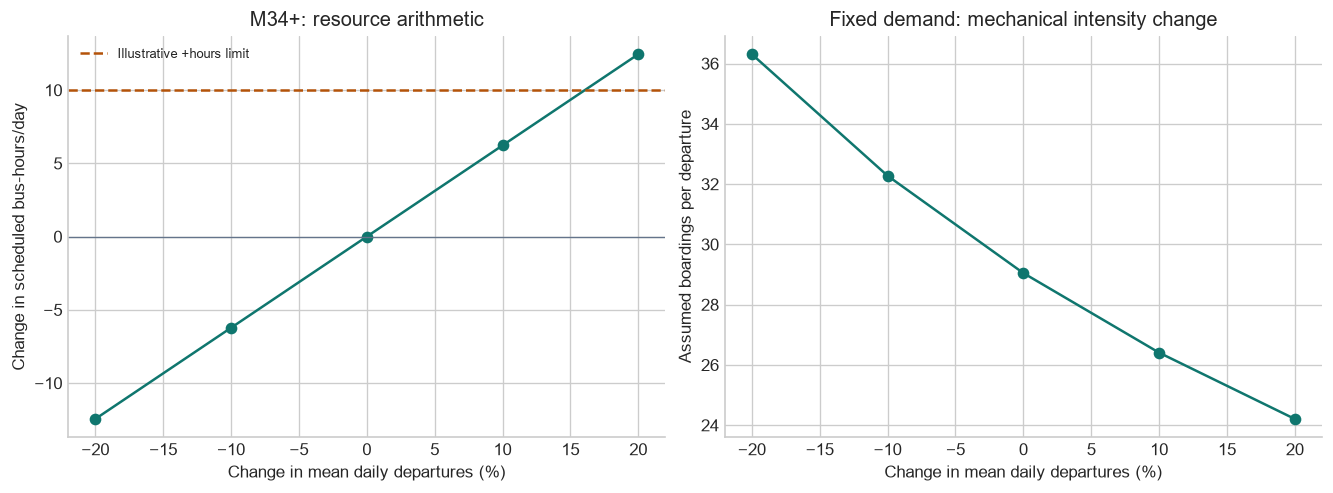

In [5]:
focus = baselines.loc[baselines.bus_route.eq(PROTOCOL["focus_route"])
                      & baselines.day_type.eq(PROTOCOL["focus_day_type"])].copy()
assert len(focus) == 1 and focus.baseline_eligible.all()
focus_comparison = comparisons.loc[
    comparisons.bus_route.eq(PROTOCOL["focus_route"])
    & comparisons.day_type.eq(PROTOCOL["focus_day_type"])].sort_values("frequency_factor").copy()
display(focus_comparison[[
    "bus_route", "day_type", "frequency_factor", "mean_departures", "scenario_mean_departures",
    "delta_mean_bus_hours", "scenario_mean_boardings", "scenario_boardings_per_departure",
    "change_boardings_per_departure_fraction", "arithmetic_status"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot((focus_comparison.frequency_factor - 1) * 100, focus_comparison.delta_mean_bus_hours,
             marker="o", color="#0f766e")
axes[0].axhline(PROTOCOL["illustrative_added_bus_hours_limit"], color="#b45309", linestyle="--",
                label="Illustrative +hours limit")
axes[0].axhline(0, color="#64748b", linewidth=.8)
axes[0].set(xlabel="Change in mean daily departures (%)", ylabel="Change in scheduled bus-hours/day",
            title=f"{PROTOCOL['focus_route']}: resource arithmetic")
axes[0].legend(fontsize=8)
axes[1].plot((focus_comparison.frequency_factor - 1) * 100,
             focus_comparison.scenario_boardings_per_departure, marker="o", color="#0f766e")
axes[1].set(xlabel="Change in mean daily departures (%)", ylabel="Assumed boardings per departure",
            title="Fixed demand: mechanical intensity change")
fig.savefig(FIGURES / "focus_frequency_tradeoff.png", bbox_inches="tight")
plt.show()

## 5. Compare the stated arithmetic limits

Compare four budgets, including an unspecified limit. Unspecified is not a passing budget check.
A retained-service floor applies to mean departures only. It does not protect every time of
day, route branch, transfer or individual passenger connection.

,budget_label,frequency_factor,delta_mean_bus_hours,retention_limit_pass,added_hours_limit_pass,arithmetic_status
0,+0 h/day,0.8,-12.451,True,True,within_declared_arithmetic_limits
1,+0 h/day,0.9,-6.225,True,True,within_declared_arithmetic_limits
2,+0 h/day,1.0,0.000,True,True,within_declared_arithmetic_limits
3,+0 h/day,1.1,6.225,True,False,exceeds_added_hours_limit
4,+0 h/day,1.2,12.451,True,False,exceeds_added_hours_limit
5,+5 h/day,0.8,-12.451,True,True,within_declared_arithmetic_limits
6,+5 h/day,0.9,-6.225,True,True,within_declared_arithmetic_limits
7,+5 h/day,1.0,0.000,True,True,within_declared_arithmetic_limits
8,+5 h/day,1.1,6.225,True,False,exceeds_added_hours_limit
9,+5 h/day,1.2,12.451,True,False,exceeds_added_hours_limit


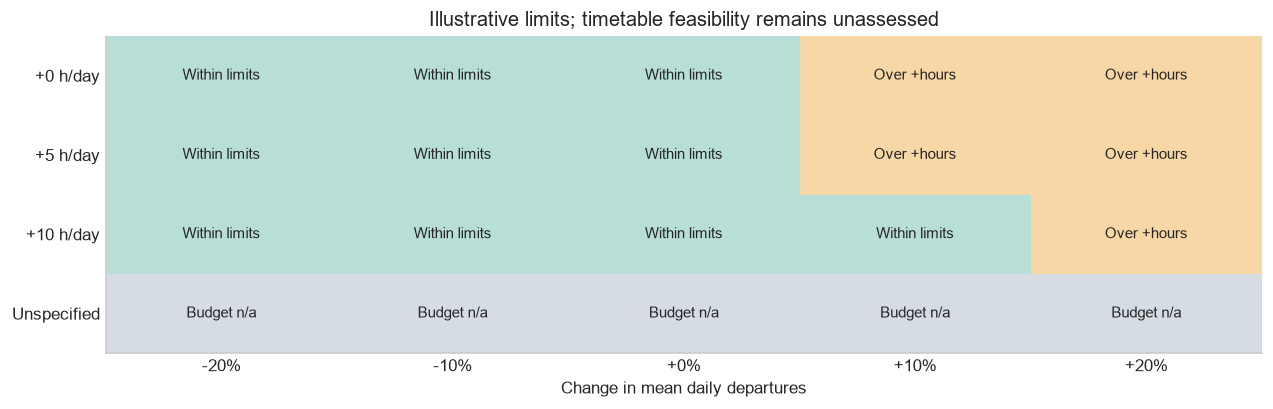

In [6]:
budget_frames = []
for limit in PROTOCOL["budget_limits"]:
    for factor in PROTOCOL["frequency_factors"]:
        part = compare_frequency(focus, factor, max_added_bus_hours=limit,
                                 minimum_retained_fraction=PROTOCOL["minimum_retained_fraction"])
        part["budget_label"] = "Unspecified" if limit is None else f"+{limit:g} h/day"
        budget_frames.append(part)
budget_sensitivity = pd.concat(budget_frames, ignore_index=True)
display(budget_sensitivity[["budget_label", "frequency_factor", "delta_mean_bus_hours",
                            "retention_limit_pass", "added_hours_limit_pass", "arithmetic_status"]].round(3))
matrix = budget_sensitivity.pivot(index="budget_label", columns="frequency_factor", values="arithmetic_status")
matrix = matrix.reindex(["+0 h/day", "+5 h/day", "+10 h/day", "Unspecified"])
codes = {"within_declared_arithmetic_limits": 0, "exceeds_added_hours_limit": 1,
         "within_retention_limit_budget_unspecified": 2}
labels = {0: "Within limits", 1: "Over +hours", 2: "Budget n/a"}
values = matrix.apply(lambda col: col.map(codes)).to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(10.5, 3.3))
ax.imshow(values, cmap=ListedColormap(["#b8dfd7", "#f8d7a6", "#d5dce4"]), vmin=0, vmax=2, aspect="auto")
ax.grid(False)
ax.set(yticks=range(len(matrix)), yticklabels=matrix.index, xticks=range(len(matrix.columns)),
       xticklabels=[f"{(factor-1)*100:+.0f}%" for factor in matrix.columns],
       xlabel="Change in mean daily departures", title="Illustrative limits; timetable feasibility remains unassessed")
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        ax.text(j, i, labels[values[i, j]], ha="center", va="center", fontsize=9)
fig.savefig(FIGURES / "budget_sensitivity.png", bbox_inches="tight")
plt.show()

## 6. Keep demand sensitivity independent of service change

Cross the same frequency factors with assumed demand multipliers 0.9, 1.0 and 1.1.
These are analyst assumptions, not estimated elasticity or forecast outputs. In particular,
November forecasts are not joined to July–September schedules to infer future service needs.

The intensity ratio becomes demand_factor / frequency_factor. A +20% service, +10% assumed-demand
case has 8.33% lower boarding intensity by arithmetic, not evidence of a passenger response.

,frequency_factor,demand_factor,scenario_mean_boardings,scenario_boardings_per_departure,delta_mean_bus_hours
0,0.8,0.9,4500.695,32.679,-12.451
1,0.9,0.9,4500.695,29.048,-6.225
2,1.0,0.9,4500.695,26.143,0.000
3,1.1,0.9,4500.695,23.766,6.225
4,1.2,0.9,4500.695,21.786,12.451
5,0.8,1.0,5000.772,36.309,-12.451
6,0.9,1.0,5000.772,32.275,-6.225
7,1.0,1.0,5000.772,29.048,0.000
8,1.1,1.0,5000.772,26.407,6.225
9,1.2,1.0,5000.772,24.206,12.451


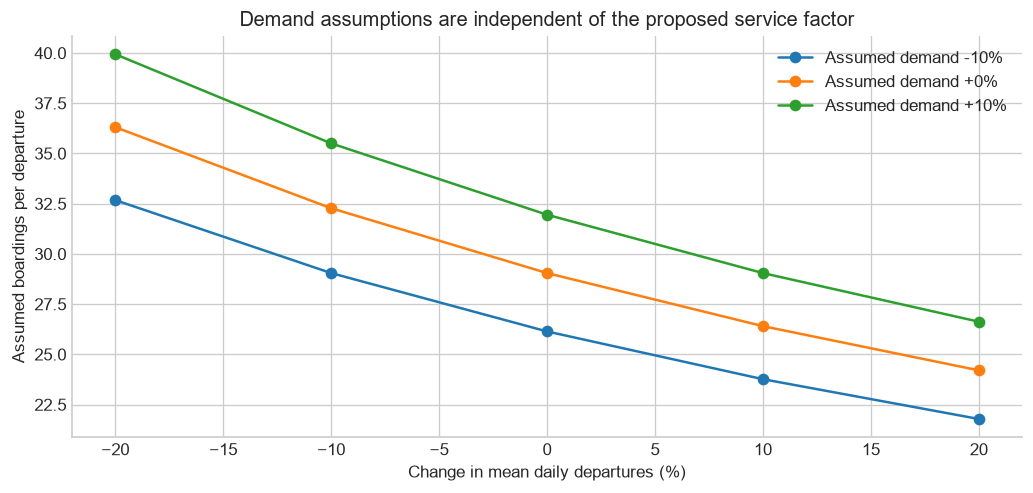

In [7]:
demand_frames = []
for demand_factor in PROTOCOL["demand_factors"]:
    for factor in PROTOCOL["frequency_factors"]:
        demand_frames.append(compare_frequency(
            focus, factor, demand_factor=demand_factor,
            max_added_bus_hours=PROTOCOL["illustrative_added_bus_hours_limit"],
            minimum_retained_fraction=PROTOCOL["minimum_retained_fraction"]))
demand_sensitivity = pd.concat(demand_frames, ignore_index=True)
display(demand_sensitivity[["frequency_factor", "demand_factor", "scenario_mean_boardings",
                            "scenario_boardings_per_departure", "delta_mean_bus_hours"]].round(3))
fig, ax = plt.subplots(figsize=(8.5, 4))
for multiplier, part in demand_sensitivity.groupby("demand_factor"):
    part = part.sort_values("frequency_factor")
    ax.plot((part.frequency_factor - 1) * 100, part.scenario_boardings_per_departure,
             marker="o", label=f"Assumed demand {(multiplier-1)*100:+.0f}%")
ax.set(xlabel="Change in mean daily departures (%)", ylabel="Assumed boardings per departure",
       title="Demand assumptions are independent of the proposed service factor")
ax.legend()
fig.savefig(FIGURES / "independent_demand_sensitivity.png", bbox_inches="tight")
plt.show()

## 7. Compare equal-hour transfers in both directions

Transfer five mean daily scheduled bus-hours between M34+ and M34A+, plus a zero-transfer
control. Both routes must have exactly the same matched observation dates and eligible
baselines. Each route's demand stays fixed. The same transferred hours can imply different
departure changes because their aggregate hour/departure exposures differ.

This is a manually specified illustration, not a recommendation. Shared stops and exclusive
coverage are September-snapshot context; they do not establish that a transfer preserves
passenger journeys. Layovers, deadheading, vehicle blocks, crew rules and peak fleet needs
are not included.

,case_id,transfer_bus_hours,baseline_total_mean_bus_hours,scenario_total_mean_bus_hours,net_mean_departures_change,retention_limits_pass,arithmetic_status
0,zero_transfer,0.0,130.34912,130.34912,0.0000,True,within_stated_transfer_limits
1,M34_to_M34A,5.0,130.34912,130.34912,-1.6075,True,within_stated_transfer_limits
2,M34A_to_M34,5.0,130.34912,130.34912,1.6075,True,within_stated_transfer_limits


,case_id,bus_route,transfer_role,mean_departures,scenario_mean_departures,delta_mean_bus_hours,scenario_boardings_per_departure
0,zero_transfer,M34+,donor,172.158,172.158,0.0,29.048
1,zero_transfer,M34A+,recipient,166.421,166.421,0.0,29.896
2,M34_to_M34A,M34+,donor,172.158,158.331,-5.0,31.584
3,M34_to_M34A,M34A+,recipient,166.421,178.641,5.0,27.851
4,M34A_to_M34,M34A+,donor,166.421,154.201,-5.0,32.266
5,M34A_to_M34,M34+,recipient,172.158,185.985,5.0,26.888


,route_a,route_b,shared_stop_ids,jaccard,smaller_route_overlap,a_only_stop_ids,b_only_stop_ids,snapshot_id
649,M34+,M34A+,22,0.536585,0.758621,12,7,manhattan_20260903


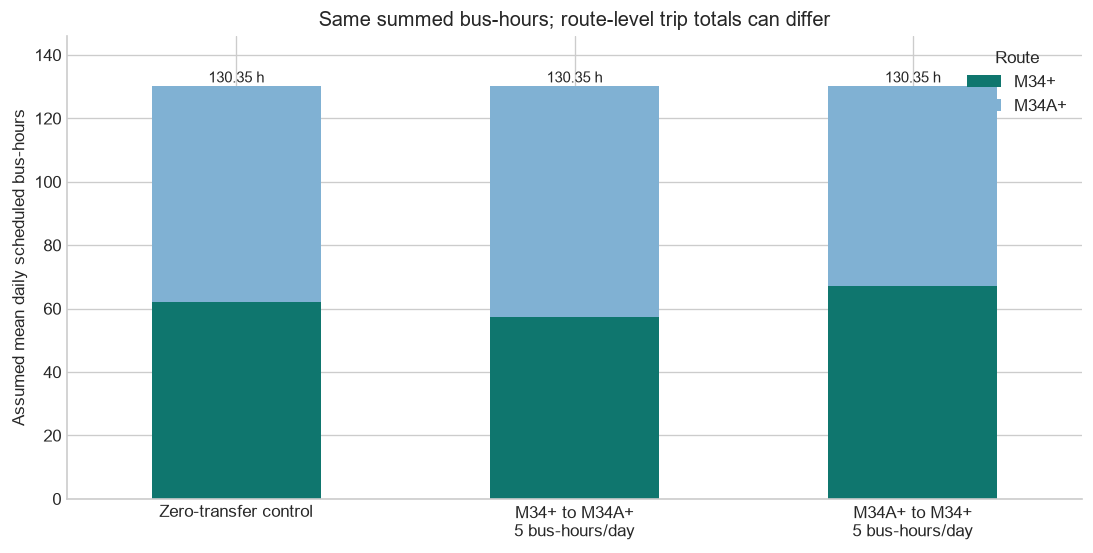

In [8]:
transfer_frames, transfer_summary_rows = [], []
for case in PROTOCOL["transfer_cases"]:
    rows, summary = transfer_bus_hours(
        baselines, case["donor"], case["recipient"], PROTOCOL["focus_day_type"], case["hours"],
        minimum_retained_fraction=PROTOCOL["minimum_retained_fraction"])
    rows["case_id"], summary["case_id"] = case["case_id"], case["case_id"]
    transfer_frames.append(rows)
    transfer_summary_rows.append(summary)
transfer_comparisons = pd.concat(transfer_frames, ignore_index=True)
transfer_summary = pd.DataFrame(transfer_summary_rows)
np.testing.assert_allclose(transfer_summary.net_mean_bus_hours_change, 0., atol=1e-9)
np.testing.assert_allclose(transfer_summary.baseline_total_mean_boardings,
                           transfer_summary.scenario_total_mean_boardings)
display(transfer_summary[["case_id", "transfer_bus_hours", "baseline_total_mean_bus_hours",
                          "scenario_total_mean_bus_hours", "net_mean_departures_change",
                          "retention_limits_pass", "arithmetic_status"]].round(5))
display(transfer_comparisons[["case_id", "bus_route", "transfer_role", "mean_departures",
                              "scenario_mean_departures", "delta_mean_bus_hours",
                              "scenario_boardings_per_departure"]].round(3))
overlap = pd.read_csv(DATA / "route_overlap.csv")
pair = {"M34+", "M34A+"}
corridor_context = overlap.loc[overlap.route_a.isin(pair) & overlap.route_b.isin(pair)].copy()
assert len(corridor_context) == 1
display(corridor_context)
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_hours = transfer_comparisons.pivot(index="case_id", columns="bus_route", values="scenario_mean_bus_hours")
plot_hours = plot_hours.reindex([case["case_id"] for case in PROTOCOL["transfer_cases"]])
plot_hours[["M34+", "M34A+"]].plot.bar(stacked=True, ax=ax, color=["#0f766e", "#80b1d3"], rot=0)
ax.set(xticklabels=["Zero-transfer control", "M34+ to M34A+\n5 bus-hours/day", "M34A+ to M34+\n5 bus-hours/day"],
       xlabel="", ylabel="Assumed mean daily scheduled bus-hours",
       title="Same summed bus-hours; route-level trip totals can differ")
for i, total in enumerate(plot_hours.sum(axis=1)):
    ax.text(i, total + 1, f"{total:.2f} h", ha="center", fontsize=9)
ax.set_ylim(0, plot_hours.sum(axis=1).max() * 1.12)
ax.legend(title="Route")
fig.savefig(FIGURES / "paired_bus_hour_transfers.png", bbox_inches="tight")
plt.show()

## 8. Retain withheld and failed-limit cases

Keep source-withheld results missing. Keep numerical arithmetic for a failed declared limit,
but label the failure rather than discarding it. Passing arithmetic limits never changes the
unassessed timetable status. Invalid factors are rejected explicitly.

In [9]:
floor_case = compare_frequency(focus, .75, max_added_bus_hours=10.,
                               minimum_retained_fraction=PROTOCOL["minimum_retained_fraction"])
floor_case["example"] = "Below the illustrative retained-service floor"
unknown_budget_case = compare_frequency(focus, 1.1, max_added_bus_hours=None)
unknown_budget_case["example"] = "No additional-hours budget supplied"
source_projection = compare_frequency(
    baselines.loc[~baselines.baseline_eligible], 1.2, max_added_bus_hours=10.)
source_projection["example"] = "Source clarification: no projected service result"
constraint_examples = pd.concat([floor_case, unknown_budget_case, source_projection], ignore_index=True)
display(constraint_examples[["example", "bus_route", "day_type", "baseline_status",
                             "scenario_mean_departures", "retention_limit_pass",
                             "added_hours_limit_pass", "arithmetic_status", "timetable_feasibility"]])
assert source_projection.scenario_mean_departures.isna().all()
assert source_projection.added_hours_limit_pass.isna().all()
try:
    compare_frequency(focus, 0.)
except ValueError as exc:
    print("Rejected nonpositive frequency factor:", str(exc))
print("No timetable was generated and no service change was applied.")

,example,bus_route,day_type,baseline_status,scenario_mean_departures,retention_limit_pass,added_hours_limit_pass,arithmetic_status,timetable_feasibility
0,Below the illustrative retained-service floor,M34+,Weekday,eligible,129.118421,False,True,below_retained_service_limit,not_assessed
1,No additional-hours budget supplied,M34+,Weekday,eligible,189.373684,True,<NA>,within_retention_limit_budget_unspecified,not_assessed
2,Source clarification: no projected service result,M98,Weekday,source_clarification_required,NaN,<NA>,<NA>,withheld,not_assessed
3,Source clarification: no projected service result,M98,Saturday,source_clarification_required,NaN,<NA>,<NA>,withheld,not_assessed
4,Source clarification: no projected service result,M98,Sunday,source_clarification_required,NaN,<NA>,<NA>,withheld,not_assessed


Rejected nonpositive frequency factor: frequency_factor is outside the permitted arithmetic domain
No timetable was generated and no service change was applied.


## 9. Describe budget exposure across the eligible network

These are alternative cases, not a combined proposal. Compare how many route/day-type
additions fit the same illustrative ten-hour limit. Eligibility excludes the source-clarification
route. Counts describe the imposed limit, not feasible or desirable operational changes.

arithmetic_status          within_declared_arithmetic_limits  \
day_type frequency_factor                                      
Weekday  1.1                                              14   
         1.2                                               5   
Saturday 1.1                                              19   
         1.2                                               9   
Sunday   1.1                                              23   
         1.2                                              11   

arithmetic_status          exceeds_added_hours_limit  
day_type frequency_factor                             
Weekday  1.1                                      26  
         1.2                                      35  
Saturday 1.1                                      21  
         1.2                                      31  
Sunday   1.1                                      17  
         1.2                                      29

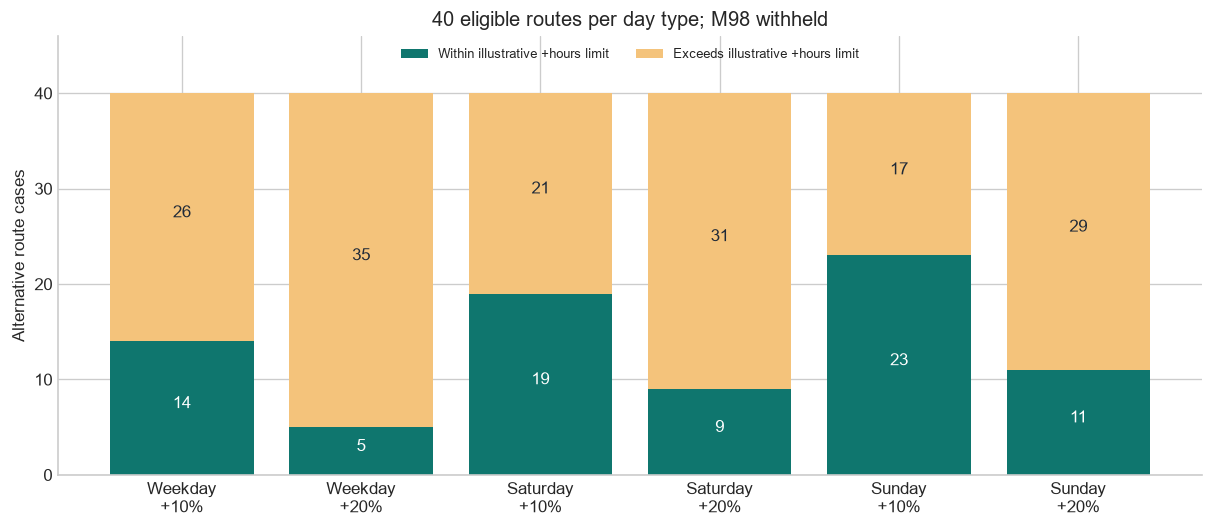

In [10]:
eligible_additions = comparisons.loc[comparisons.baseline_eligible & comparisons.frequency_factor.gt(1.)]
cohort_cost = eligible_additions.groupby(["day_type", "frequency_factor", "arithmetic_status"]).size().unstack(
    "arithmetic_status").reindex(columns=["within_declared_arithmetic_limits", "exceeds_added_hours_limit"],
                                 fill_value=0).fillna(0)
cohort_order = [(kind, factor) for kind in ["Weekday", "Saturday", "Sunday"] for factor in [1.1, 1.2]]
cohort_cost = cohort_cost.reindex(cohort_order)
display(cohort_cost.astype(int))
fig, ax = plt.subplots(figsize=(10, 4.3))
x = np.arange(len(cohort_cost))
within = cohort_cost.within_declared_arithmetic_limits
over = cohort_cost.exceeds_added_hours_limit
ax.bar(x, within, color="#0f766e", label="Within illustrative +hours limit")
ax.bar(x, over, bottom=within, color="#f4c37b", label="Exceeds illustrative +hours limit")
for i, (a, b) in enumerate(zip(within, over)):
    if a: ax.text(i, a / 2, int(a), ha="center", color="white")
    if b: ax.text(i, a + b / 2, int(b), ha="center", color="#1f2937")
ax.set(xticks=x, xticklabels=[f"{kind}\n{(factor-1)*100:+.0f}%" for kind, factor in cohort_order],
       ylabel="Alternative route cases", ylim=(0, 46),
       title="40 eligible routes per day type; M98 withheld")
ax.legend(loc="upper center", ncols=2, fontsize=8)
fig.savefig(FIGURES / "network_added_hours_limit.png", bbox_inches="tight")
plt.show()

## 10. State what is and is not established

The comparison preserves historical source facts and exposes scenario assumptions and limits.
Do not rank alternatives by boarding intensity alone. A smaller mechanical rate can require
more service, and reduced service can harm access despite unchanged route geometry.
No forecast is promoted, no elastic demand response is inferred and no passenger benefit is measured.

In [11]:
plus_twenty = focus_comparison.loc[focus_comparison.frequency_factor.eq(1.2)].iloc[0]
status_counts = comparisons.arithmetic_status.value_counts().to_dict()
interpretation = (
    f"**Historical arithmetic component:** {len(baselines)} route/day-type baselines; "
    f"{int(baselines.baseline_eligible.sum())} eligible and "
    f"{int((~baselines.baseline_eligible).sum())} withheld. "
    f"{len(comparisons)} alternative frequency cases retain all unavailable projections.\n\n"
    f"For {PROTOCOL['focus_route']} weekdays, +20% mean departures changes the average from "
    f"{plus_twenty.mean_departures:.2f} to {plus_twenty.scenario_mean_departures:.2f}, "
    f"adds {plus_twenty.delta_mean_bus_hours:.2f} scheduled bus-hours/day, and changes "
    f"boardings per departure by {plus_twenty.change_boardings_per_departure_fraction:.2%} "
    f"under fixed demand. Its declared-limit status is {plus_twenty.arithmetic_status}.\n\n"
    "Both directional five-hour transfer illustrations conserve total scheduled bus-hours "
    "while trip totals can change. Timetable, fleet, crew, capacity, access and benefits remain "
    "unassessed. Results are scenario arithmetic, not service recommendations."
)
display(Markdown(interpretation))
display(pd.DataFrame([{"arithmetic_status": key, "cases": value} for key, value in status_counts.items()]))

**Historical arithmetic component:** 123 route/day-type baselines; 120 eligible and 3 withheld. 615 alternative frequency cases retain all unavailable projections.

For M34+ weekdays, +20% mean departures changes the average from 172.16 to 206.59, adds 12.45 scheduled bus-hours/day, and changes boardings per departure by -16.67% under fixed demand. Its declared-limit status is exceeds_added_hours_limit.

Both directional five-hour transfer illustrations conserve total scheduled bus-hours while trip totals can change. Timetable, fleet, crew, capacity, access and benefits remain unassessed. Results are scenario arithmetic, not service recommendations.

,arithmetic_status,cases
0,within_declared_arithmetic_limits,441
1,exceeds_added_hours_limit,159
2,withheld,15


## 11. Save reusable cases and preserve the earlier analyses

Save baselines, all alternatives, the fixed example, budget/demand sensitivity, transfer
arithmetic and failure cases. The manifest records source/code/runtime identities, assumptions,
output fingerprints and earlier-artifact preservation. No operational timetable or model is saved.

In [12]:
import nbformat

tables = {
    "scenario_baselines": baselines, "frequency_comparisons": comparisons, "case_summary": case_summary,
    "focus_comparison": focus_comparison, "budget_sensitivity": budget_sensitivity,
    "demand_sensitivity": demand_sensitivity, "transfer_comparisons": transfer_comparisons,
    "transfer_summary": transfer_summary, "transfer_corridor_context": corridor_context,
    "constraint_examples": constraint_examples,
}
products = {}
for name, frame in tables.items():
    path = OUT / f"{name}.csv"
    frame.to_csv(path, index=False)
    products[path.relative_to(ROOT).as_posix()] = {
        "sha256": sha256(path), "rows": len(frame), "columns": frame.columns.tolist()}
for path in sorted(FIGURES.glob("*.png")):
    products[path.relative_to(ROOT).as_posix()] = {"sha256": sha256(path)}
for path, expected in protected_before.items():
    assert sha256(ROOT / path) == expected, path
notebook_path = ROOT / "notebooks/new_york/11_service_frequency_scenarios.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)
source = "\n\n".join(c.source for c in notebook.cells if c.cell_type == "code")
manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "scope": "historical_mean_daily_arithmetic",
    "protocol": PROTOCOL, "routes": sorted(baselines.bus_route.unique()), "member_route_dates": len(members),
    "common_dates": members.payment_date.nunique(), "baseline_profiles": len(baselines),
    "eligible_profiles": int(baselines.baseline_eligible.sum()),
    "withheld_profiles": int((~baselines.baseline_eligible).sum()), "frequency_cases": len(comparisons),
    "status_counts": status_counts, "transfer_cases": len(transfer_summary),
    "source_code": {"scripts/service_scenarios.py": sha256(ROOT / "scripts/service_scenarios.py")},
    "notebook_code_sha256": hashlib.sha256(source.encode()).hexdigest(),
    "input_files": input_hashes, "products": products, "protected_original_files": protected_before,
    "runtime": {"python": platform.python_version(), **{
        name: importlib.metadata.version(name) for name in ["numpy", "pandas", "matplotlib"]}},
    "operational_feasibility_established": False, "forecast_used_as_demand": False,
    "demand_response_estimated": False, "passenger_benefit_measured": False,
    "integer_timetable_generated": False, "automatic_service_change": False,
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(REPORT / "FINDINGS.md").write_text("# Historical frequency-scenario arithmetic\n\n" + interpretation,
                                   encoding="utf-8")
print("Saved tables:", len(tables), "| Figures:", len(list(FIGURES.glob("*.png"))))
print("Earlier artifacts verified unchanged:", len(protected_before))
print("Products:", OUT.relative_to(ROOT).as_posix())
print("Independent verification: python scripts/audit_service_scenarios.py")

Saved tables: 10 | Figures: 5
Earlier artifacts verified unchanged: 197
Products: data/processed/new_york/service_scenarios
Independent verification: python scripts/audit_service_scenarios.py


## Interpretation and next use

This component is suitable for an explicitly labelled planning prototype. The baseline period,
source status, demand assumption, arithmetic limits and unassessed feasibility must travel with
every displayed result. Mean daily cases are not actual departure plans.

The next application milestone is a **Streamlit dashboard** connecting historical evidence,
experimental forecasts, route profiles, review reasons and these scenario comparisons.
Operational scheduling, route redesign and forecast promotion remain separate requirements.